# Performace metrics

# Confusion matrix

In [1]:
# libraries
import pandas as pd
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_breast_cancer

In [2]:
# load the inbuild dataset
dataset = load_breast_cancer()

In [3]:
print(dir(dataset))

['DESCR', 'data', 'data_module', 'feature_names', 'filename', 'frame', 'target', 'target_names']


In [4]:
print(dataset.DESCR)

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [5]:
x = dataset.data
y = dataset.target

In [6]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state = 42)

In [7]:
# scaling data
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [8]:
# import different ML algorithm
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

In [9]:
# model object creation
log_model = LogisticRegression()
d_model = DecisionTreeClassifier()
knn_model = KNeighborsClassifier(n_neighbors= 7)
nb_model = GaussianNB()
svm_model = SVC()

In [10]:
# training of all the mL algorithm
log_model.fit(x_train_scaled,y_train)
d_model.fit(x_train_scaled,y_train)
knn_model.fit(x_train_scaled,y_train)
nb_model.fit(x_train_scaled,y_train)
svm_model.fit(x_train_scaled,y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [11]:
# score
log_model.score(x_test_scaled,y_test)

0.9736842105263158

In [12]:
d_model.score(x_test_scaled,y_test)

0.9298245614035088

In [13]:
knn_model.score(x_test_scaled,y_test)

0.9473684210526315

In [14]:
nb_model.score(x_test_scaled,y_test)

0.9649122807017544

In [15]:
svm_model.score(x_test_scaled,y_test)

0.9824561403508771

In [16]:
# making prediction
y_pred_log = log_model.predict(x_test_scaled)
y_pred_dtree = d_model.predict(x_test_scaled)
y_pred_knn = knn_model.predict(x_test_scaled)
y_pred_nb = nb_model.predict(x_test_scaled)
y_pred_svm = svm_model.predict(x_test_scaled)

Text(20.72222222222222, 0.5, 'Actual values')

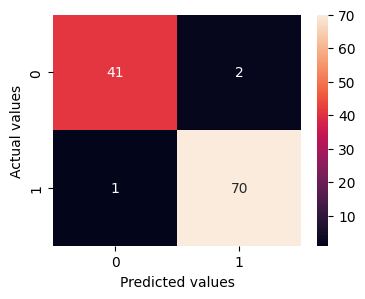

In [17]:
# y_test is the "acutal" target values

# construct the confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize = (4,3))
cm_log = confusion_matrix(y_test,y_pred_log)
sns.heatmap(cm_log, annot = True)
plt.xlabel("Predicted values")
plt.ylabel("Actual values")

Text(20.72222222222222, 0.5, 'Actual values')

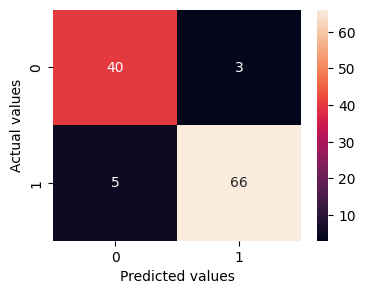

In [18]:
# confusion matrix for DT
plt.figure(figsize = (4,3))
cm_dtree = confusion_matrix(y_test,y_pred_dtree)
sns.heatmap(cm_dtree, annot = True)
plt.xlabel("Predicted values")
plt.ylabel("Actual values")


Text(20.72222222222222, 0.5, 'Actual values')

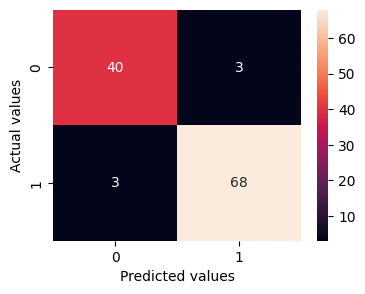

In [19]:
# construct the confusion matrix for KNN
plt.figure(figsize = (4,3))
cm_knn = confusion_matrix(y_test,y_pred_knn)
sns.heatmap(cm_knn, annot = True)
plt.xlabel("Predicted values")
plt.ylabel("Actual values")

Text(20.72222222222222, 0.5, 'Actual values')

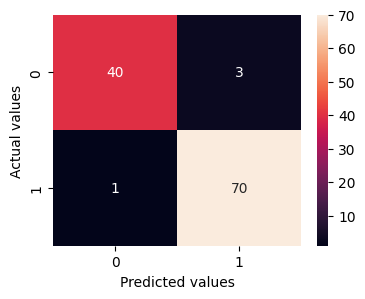

In [20]:
# construct the confusion matrix for NB
plt.figure(figsize = (4,3))
cm_nb = confusion_matrix(y_test,y_pred_nb)
sns.heatmap(cm_nb, annot = True)
plt.xlabel("Predicted values")
plt.ylabel("Actual values")

Text(20.72222222222222, 0.5, 'Actual values')

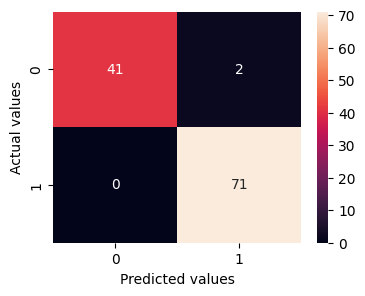

In [21]:
# construct the confusion matrix for SVM
plt.figure(figsize = (4,3))
cm_svm = confusion_matrix(y_test,y_pred_svm)
sns.heatmap(cm_svm, annot = True)
plt.xlabel("Predicted values")
plt.ylabel("Actual values")

In [22]:
# 14/11/2926
# Accuracy tells the percentage total correctly predicted value out of total predictions.
# accuracy = (tp + tn) / (tp + tn + fp + fn)

# Accuracy matrix

In [23]:
TN, FP, FN, TP  = confusion_matrix(y_test,y_pred_svm).ravel()
accuracy = (TP + TN) / (TP + TN + FP + FN)
print(accuracy)

0.9824561403508771


In [24]:
from sklearn.metrics import accuracy_score
acc = accuracy_score(y_test,y_pred_svm)
acc

0.9824561403508771

In [25]:
# Don't use the accuracy matrix if the data is imbalance.

# Precision

In [26]:
# Precision = (TP) / (TP + FP)

In [27]:
precision = (TP) / (TP + FP)
precision

0.9726027397260274

In [28]:
from sklearn.metrics import precision_score
pc = precision_score(y_test,y_pred_svm)
pc

0.9726027397260274

In [29]:
# precision should be used when we are concerned about type1 error. (FP)
# FP example : if a mail is "not spam" and the model predicted it as spam
# type1 error has more weightage than type2 error. 
# fp value must be minimum to make sure Not Spam don't goo in spam section.

In [30]:
# Recall or senstivity
# out of all actual positive valeus how many are predicted correctly. It is also known as recall(True postive rate(TPR))
# use recall when we have type2 error(FN)
# recall is used when a false negative is more important like a patient is covid positive but the model detected it as negative, it will cause a great impact on healthcare

In [31]:
recall = (TP) / (TP + FN)
recall

1.0

In [32]:
from sklearn.metrics import recall_score
r = recall_score(y_test, y_pred_svm)
r

1.0

# Specificity & FPR

In [33]:
# specificity = (TN) / (TN + FP)
# FPR: {1 - specificity} or (FP) / (TN + FP)
# out of all actual negative values how many are predicted correctly.
# providing loan to Bad credit score candidate (FP) is not a good idea.

In [34]:
specificity = (TN) / (TN + FP)
FPR = 1 - specificity
print(f"specificity: {specificity}")
print(f"FPR: {1 - specificity}")

specificity: 0.9534883720930233
FPR: 0.046511627906976716


In [35]:
# There is no inbuilt function for specificity and FPR in sklearn

# F1-Score

In [36]:
F1_score = 2 * ( (recall  * pc) / (recall + pc) )
print(F1_score)

0.9861111111111112


In [37]:
from sklearn.metrics import f1_score
f1 = f1_score(y_test, y_pred_svm)
f1

0.9861111111111112

# ROC curve

In [38]:
# AUC is Area under the ROC curve. More will be the area better will be the performance.
# ROC curve is a graphical representation used to evaluate the performance of a classification model at all classification model.

In [39]:
from sklearn.metrics import roc_curve
roc_curve(y_test, y_pred_svm)

(array([0.        , 0.04651163, 1.        ]),
 array([0., 1., 1.]),
 array([inf,  1.,  0.]))